# Experiment B — can a graph model classify disease better than a flat one?

The headline question of the graph extension: under **honest** evaluation
(leave-one-project-out, every test sample from a study the model never saw), does a model
that knows the taxonomy beat the committed flat baselines at telling cases from controls?

| model | what it is | role |
|---|---|---|
| logistic regression, gradient boosting | the committed Phase 5e flat baselines on 419 CLR features | what to beat |
| **GCN, per-sample taxonomy** | one 666-node taxonomy tree per sample, the sample's CLR on the leaves; graphs are disjoint, so it cannot leak | **the headline model** |
| GCN, shuffled tree | the same GCN on a tree with the same shape but parents shuffled within each rank | does the *real* taxonomy matter, or any tree? |
| MLP, GCN-sized | a flat MLP with the GCN's parameter count | did the GCN win by structure or by size? |
| GraphSAGE / GAT on G1 | the one-big-graph models, held-out samples as receivers only (Experiment C showed this leaks nothing) | the other framing |
| MLP, SAGE-sized / GAT-sized | flat MLPs with those models' parameter counts | their size-matched controls |

**When is a win a win?** The headline claim is licensed only if, for IBD, the GCN's
leave-one-project-out AUC beats the better of logistic regression / gradient boosting
**and** the GCN-sized MLP by more than the fold-to-fold sd. IBD has only 4 studies, so
only 4 folds, and that sd is wide: a 0.01 "win" is nothing. This threshold is stated here,
before the results.

Diseases: IBD (primary), HIV and NAFLD (secondary), and T1D, asthma and cancer_other for
completeness: Phase 5 and the leakage experiment found nothing defensible in those three,
and a graph model finding something there would be more alarming than exciting. Three
model seeds each. Pretraining (the "with pretraining" rows) comes later.

Each (disease, model, seed) job writes its own file under
`data/processed/graph_disease_runs/`, and finished jobs are skipped, so an interrupted run
resumes. Jobs run in parallel processes: a single GCN job uses only part of the CPU.

Outputs: `reports/graph_disease_cv.csv` (one row per fold), `reports/graph_disease_summary.csv`,
`reports/figures/phase7_disease_lopo.png`.

## Setup

In [1]:
import os
import sys
import time
import warnings
from concurrent.futures import ProcessPoolExecutor, as_completed
from pathlib import Path

import numpy as np
import pandas as pd
import yaml

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
os.environ["PYTHONPATH"] = str(ROOT)  # worker processes import `src` too

from src import differential as diff
from src import graph_disease as gd

REPORTS = ROOT / "reports"
FIGURES = REPORTS / "figures"
PROCESSED = ROOT / "data" / "processed"
RUN_DIR = PROCESSED / "graph_disease_runs"

with open(ROOT / "config" / "params.yaml") as f:
    params = yaml.safe_load(f)
SEED = params["seed"]
dcfg = params["differential"]
gcfg = params["graph"]
bcfg = gcfg["disease"]

import torch
import torch_geometric
warnings.filterwarnings("ignore")

print(f"seed={SEED}  torch={torch.__version__}  torch_geometric={torch_geometric.__version__}")
print(f"diseases={bcfg['categories']}  models={bcfg['models']}  seeds={bcfg['seeds']}")
print(f"epochs={gcfg['train']['epochs']}  parallel jobs={bcfg['parallel_jobs']} x "
      f"{bcfg['threads_per_job']} threads")

C:\Users\Jadrovski\vnp\MicroWave\.venv\Lib\site-packages\torch\jit\_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


seed=42  torch=2.14.0+cpu  torch_geometric=2.8.1
diseases=['IBD', 'HIV', 'NAFLD', 'T1D', 'asthma', 'cancer_other']  models=['gcn', 'gcn_shuffled', 'sage_g1', 'gat_g1', 'mlp_gcn', 'mlp_sage', 'mlp_gat']  seeds=[42, 43, 44]
epochs=60  parallel jobs=3 x 4 threads


## 1 — Harness check: the committed flat baselines, re-run here

`differential.batch_leakage_cv` with the committed settings, on the same populations, before
any graph number below is read. The folds and test samples must be identical. Logistic
regression must reproduce `reports/classifier_cv.csv` exactly. Gradient boosting must land
within fold noise of it, the bar this check was specified with. Re-runs reproduce NAFLD
exactly but move individual IBD and HIV folds by up to ~0.02 AUC. The code, settings,
scikit-learn version and input files are all unchanged since that file was written, and
today's runs are bit-identical to each other at any thread count. The cause is not
identified; the most likely is that the committed file came from an uncommitted variant of
the Phase 5 code. The tables below use today's re-run, so every model in them shares one
environment; the committed means are shown beside it.

In [2]:
cohort = pd.read_parquet(PROCESSED / "cohort_within_project.parquet")
frame = diff.build_analysis_frame(cohort, dcfg["category_groups"])
committed = pd.read_csv(REPORTS / "classifier_cv.csv")
blcfg = dcfg["batch_leakage"]

flat_parts = []
for cat in bcfg["categories"]:
    samples = frame.loc[frame["disease_category"] == cat, "sample"].unique()
    clr_df, _ = diff.load_clr(PROCESSED / "abund_clr.parquet", samples)
    flat_parts.append(diff.batch_leakage_cv(
        clr_df, frame, cat, SEED, n_splits=blcfg["cv_folds"], models=blcfg["models"],
        logreg_C=blcfg["logreg_C"], gboost_max_iter=blcfg["gboost_max_iter"],
        gboost_learning_rate=blcfg["gboost_learning_rate"],
        gboost_max_depth=blcfg["gboost_max_depth"]))
flat = pd.concat(flat_parts, ignore_index=True)

key = ["disease_category", "model", "cv_scheme", "fold"]
check = flat.merge(committed, on=key, suffixes=("", "_committed"))
assert len(check) == len(flat) == len(committed[committed["disease_category"].isin(bcfg["categories"])])
assert (check["n_test"] == check["n_test_committed"]).all()
assert (check["n_test_pos"] == check["n_test_pos_committed"]).all()

lr = check[check["model"] == "logreg"]
assert np.allclose(lr["auc"], lr["auc_committed"], atol=1e-9), "logistic regression not reproduced"

means = (check.groupby(["disease_category", "model", "cv_scheme"])
         .agg(auc_rerun=("auc", "mean"), auc_committed=("auc_committed", "mean"),
              committed_fold_sd=("auc_committed", "std"),
              max_fold_diff=("auc", lambda s: np.abs(s - check.loc[s.index, "auc_committed"]).max())))
means["mean_diff"] = means["auc_rerun"] - means["auc_committed"]
assert (means["mean_diff"].abs() <= means["committed_fold_sd"]).all(), "not within fold noise"
print(f"folds and test samples identical for all {len(check)} committed folds; logistic "
      f"regression exact; gradient boosting within fold noise (largest single-fold difference "
      f"{means['max_fold_diff'].max():.3f})")
means.round(3)

folds and test samples identical for all 98 committed folds; logistic regression exact; gradient boosting within fold noise (largest single-fold difference 0.035)


auc_rerun  auc_committed  \
disease_category model  cv_scheme                                     
HIV              gboost leave_project_out      0.532          0.532   
                        random_kfold           0.775          0.785   
                 logreg leave_project_out      0.542          0.542   
                        random_kfold           0.680          0.680   
IBD              gboost leave_project_out      0.728          0.730   
                        random_kfold           0.820          0.819   
                 logreg leave_project_out      0.701          0.701   
                        random_kfold           0.747          0.747   
NAFLD            gboost leave_project_out      0.673          0.673   
                        random_kfold           0.757          0.757   
                 logreg leave_project_out      0.626          0.626   
                        random_kfold           0.761          0.761   
T1D              gboost leave_project_out      0.480          0.480   
                        random_kfold           0.579          0.579   
                 logreg leave_project_out      0.401          0.401   
                        random_kfold           0.614          0.614   
asthma           gboost leave_project_out      0.545          0.546   
                        random_kfold           0.606          0.605   
                 logreg leave_project_out      0.588          0.588   
                        random_kfold           0.598          0.598   
cancer_other     gboost leave_project_out      0.577          0.566   
                        random_kfold           0.718          0.710   
                 logreg leave_project_out      0.595          0.595   
                        random_kfold           0.640          0.640   

                                           committed_fold_sd  max_fold_diff  \
disease_category model  cv_scheme                                             
HIV              gboost leave_project_out              0.020          0.005   
                        random_kfold                   0.065          0.021   
                 logreg leave_project_out              0.027          0.000   
                        random_kfold                   0.049          0.000   
IBD              gboost leave_project_out              0.078          0.013   
                        random_kfold                   0.039          0.009   
                 logreg leave_project_out              0.072          0.000   
                        random_kfold                   0.024          0.000   
NAFLD            gboost leave_project_out              0.047          0.000   
                        random_kfold                   0.047          0.000   
                 logreg leave_project_out              0.088          0.000   
                        random_kfold                   0.055          0.000   
T1D              gboost leave_project_out              0.021          0.000   
                        random_kfold                   0.084          0.000   
                 logreg leave_project_out              0.095          0.000   
                        random_kfold                   0.117          0.000   
asthma           gboost leave_project_out              0.099          0.023   
                        random_kfold                   0.041          0.016   
                 logreg leave_project_out              0.127          0.000   
                        random_kfold                   0.034          0.000   
cancer_other     gboost leave_project_out              0.122          0.035   
                        random_kfold                   0.021          0.013   
                 logreg leave_project_out              0.075          0.000   
                        random_kfold                   0.024          0.000   

                                           mean_diff  
disease_category model  cv_scheme                     
HIV              gboost leave_p

## 2 — Model sizes, and the size-matched MLPs

Each control MLP is solved for the parameter count of its graph model (within ±10%). The
big-graph models' sizes depend on the graph, so they are measured per disease.

In [3]:
sizes = []
for cat in bcfg["categories"]:
    d = gd.category_data(ROOT, params, cat)
    for m, n in (("gcn", gd.gcn_params(d, gcfg)), ("sage_g1", gd.graph_model_params(d, gcfg, "sage_g1")),
                 ("gat_g1", gd.graph_model_params(d, gcfg, "gat_g1"))):
        sizes.append(dict(disease_category=cat, model=m, params=n,
                          samples=len(d["samples"]), cases=int(d["y"].sum()),
                          studies=len(set(d["projects"]))))
pd.DataFrame(sizes).pivot_table(index="disease_category", columns="model", values="params")

model,gat_g1,gcn,sage_g1
disease_category,,,
HIV,529857.0,184706.0,456321.0
IBD,529857.0,184706.0,456321.0
NAFLD,529857.0,184706.0,456321.0
T1D,529857.0,184706.0,456321.0
asthma,529857.0,184706.0,456321.0
cancer_other,529857.0,184706.0,456321.0


## 3 — The runs

Longest jobs first (the per-sample GCNs), spread over parallel worker processes. One line is
printed as each (disease, model, seed) finishes.

In [4]:
jobs = [(cat, m, s) for cat in bcfg["categories"] for m in bcfg["models"] for s in bcfg["seeds"]]
cost = {"gcn": 4, "gcn_shuffled": 4, "gat_g1": 2, "sage_g1": 1}
size = {cat: n for cat, n in pd.DataFrame(sizes).groupby("disease_category")["samples"].first().items()}
todo = [j for j in jobs if not gd.run_path(RUN_DIR, *j).exists()]
todo.sort(key=lambda j: -cost.get(j[1], 0.2) * size[j[0]])
print(f"{len(jobs) - len(todo)} of {len(jobs)} jobs already done; running {len(todo)}")

t_all = time.time()
if todo:
    with ProcessPoolExecutor(max_workers=bcfg["parallel_jobs"]) as pool:
        futures = {pool.submit(gd.run_job_to_file, str(ROOT), params, cat, m, s, str(RUN_DIR),
                               bcfg["threads_per_job"]): (cat, m, s) for cat, m, s in todo}
        for fut in as_completed(futures):
            cat, m, s = futures[fut]
            path, minutes = fut.result()
            res = pd.read_csv(path).groupby("cv_scheme")["auc"].mean()
            print(f"{cat:6s} {m:13s} seed {s}: LOPO AUC {res.get('leave_project_out', np.nan):.3f}  "
                  f"random AUC {res.get('random_kfold', np.nan):.3f}  [{minutes:.1f} min]", flush=True)
print(f"all jobs done in {(time.time() - t_all) / 60:.0f} min")

126 of 126 jobs already done; running 0
all jobs done in 0 min


## 4 — Results, every model beside the flat baselines

AUC averaged over folds, then over seeds (`auc_seed_sd`: the seed-to-seed spread; `fold_sd`:
the spread across folds, averaged over seeds). The flat baselines are deterministic and run
once.

In [5]:
graph_rows = pd.concat([pd.read_csv(gd.run_path(RUN_DIR, *j), keep_default_na=False, na_values=[""])
                        for j in jobs], ignore_index=True)
flat_rows = flat.assign(framing="flat", pretrained=False, seed=SEED, n_params=np.nan)
cols = ["disease_category", "model", "framing", "pretrained", "seed", "cv_scheme", "fold", "auc",
        "balanced_accuracy", "n_train", "n_test", "n_test_pos", "test_project", "n_params"]
cv_all = pd.concat([flat_rows[cols], graph_rows[cols]], ignore_index=True)
cv_all["test_project"] = cv_all["test_project"].fillna("")
cv_all.to_csv(REPORTS / "graph_disease_cv.csv", index=False)

per_seed = (cv_all.groupby(["disease_category", "model", "cv_scheme", "seed"])["auc"]
            .agg(auc="mean", fold_sd="std").reset_index())
summary = (per_seed.groupby(["disease_category", "model", "cv_scheme"])
           .agg(auc_mean=("auc", "mean"), auc_seed_sd=("auc", "std"), fold_sd=("fold_sd", "mean"))
           .reset_index())
summary.to_csv(REPORTS / "graph_disease_summary.csv", index=False)
(summary.pivot_table(index=["disease_category", "model"], columns="cv_scheme", values="auc_mean")
 .reindex(gd.ORDER, level="model").round(3))

cv_scheme                      leave_project_out  random_kfold
disease_category model                                        
HIV              logreg                    0.542         0.680
                 gboost                    0.532         0.775
                 mlp_gcn                   0.519         0.726
                 gcn_shuffled              0.517         0.748
                 gcn                       0.477         0.746
                 mlp_sage                  0.549         0.721
                 sage_g1                   0.516         0.760
                 mlp_gat                   0.545         0.728
                 gat_g1                    0.490         0.755
IBD              logreg                    0.701         0.747
                 gboost                    0.728         0.820
                 mlp_gcn                   0.740         0.839
                 gcn_shuffled              0.741         0.768
                 gcn                       0.741         0.768
                 mlp_sage                  0.739         0.835
                 sage_g1                   0.693         0.795
                 mlp_gat                   0.739         0.836
                 gat_g1                    0.687         0.771
NAFLD            logreg                    0.626         0.761
                 gboost                    0.673         0.757
                 mlp_gcn                   0.706         0.795
                 gcn_shuffled              0.679         0.760
                 gcn                       0.636         0.728
                 mlp_sage                  0.694         0.790
                 sage_g1                   0.707         0.768
                 mlp_gat                   0.698         0.796
                 gat_g1                    0.637         0.781
T1D              logreg                    0.401         0.614
                 gboost                    0.480         0.579
                 mlp_gcn                   0.406         0.648
                 gcn_shuffled              0.440         0.548
                 gcn                       0.522         0.567
                 mlp_sage                  0.400         0.641
                 sage_g1                   0.402         0.559
                 mlp_gat                   0.399         0.634
                 gat_g1                    0.402         0.568
asthma           logreg                    0.588         0.598
                 gboost                    0.545         0.606
                 mlp_gcn                   0.630         0.627
                 gcn_shuffled              0.528         0.560
                 gcn                       0.531         0.543
                 mlp_sage                  0.628         0.634
                 sage_g1                   0.536         0.528
                 mlp_gat                   0.638         0.624
                 gat_g1                    0.528         0.532
cancer_other     logreg                    0.595         0.640
                 gboost                    0.577         0.718
                 mlp_gcn                   0.574         0.678
                 gcn_shuffled              0.544         0.658
                 gcn                       0.578         0.661
                 mlp_sage                  0.576         0.676
                 sage_g1                   0.522         0.667
                 mlp_gat                   0.568         0.672
                 gat_g1                    0.513         0.657

### The pre-stated test

For each disease and each graph model: its leave-one-project-out AUC minus the best of
(logistic regression, gradient boosting, its own size-matched MLP), against its fold-to-fold
sd. A win counts only if the margin exceeds that sd.

In [6]:
lopo = summary[summary["cv_scheme"] == "leave_project_out"].set_index(["disease_category", "model"])
verdicts = []
for cat in bcfg["categories"]:
    for model, mlp in (("gcn", "mlp_gcn"), ("sage_g1", "mlp_sage"), ("gat_g1", "mlp_gat")):
        rivals = {m: lopo.loc[(cat, m), "auc_mean"] for m in ("logreg", "gboost", mlp)}
        best_rival = max(rivals, key=rivals.get)
        auc, sd = lopo.loc[(cat, model), "auc_mean"], lopo.loc[(cat, model), "fold_sd"]
        margin = auc - rivals[best_rival]
        verdicts.append(dict(disease_category=cat, model=model, lopo_auc=auc,
                             best_rival=best_rival, rival_auc=rivals[best_rival],
                             margin=margin, fold_sd=sd,
                             verdict="win" if margin > sd else
                                     ("loss" if margin < -sd else "within fold noise")))
pd.DataFrame(verdicts).round(3)

,disease_category,model,lopo_auc,best_rival,rival_auc,margin,fold_sd,verdict
0,IBD,gcn,0.741,mlp_gcn,0.740,0.001,0.068,within fold noise
1,IBD,sage_g1,0.693,mlp_sage,0.739,-0.046,0.147,within fold noise
2,IBD,gat_g1,0.687,mlp_gat,0.739,-0.051,0.095,within fold noise
3,HIV,gcn,0.477,logreg,0.542,-0.065,0.078,within fold noise
4,HIV,sage_g1,0.516,mlp_sage,0.549,-0.033,0.111,within fold noise
5,HIV,gat_g1,0.490,mlp_gat,0.545,-0.055,0.105,within fold noise
6,NAFLD,gcn,0.636,mlp_gcn,0.706,-0.071,0.073,within fold noise
7,NAFLD,sage_g1,0.707,mlp_sage,0.694,0.013,0.075,within fold noise
8,NAFLD,gat_g1,0.637,mlp_gat,0.698,-0.061,0.045,loss
9,T1D,gcn,0.522,gboost,0.480,0.043,0.105,within fold noise


### Does the real taxonomy matter?

The GCN on the real tree minus the same GCN on a shuffled tree (a different random tree per
seed), paired by seed and fold. If the gap is inside seed noise, any tree of that shape does
as well as the real one.

In [7]:
wide = per_seed.pivot_table(index=["disease_category", "cv_scheme", "seed"], columns="model",
                            values="auc")
tree_gap = (wide["gcn"] - wide["gcn_shuffled"]).groupby(["disease_category", "cv_scheme"]).agg(
    real_minus_shuffled="mean", seed_sd="std")
tree_gap["reading"] = np.where(tree_gap["real_minus_shuffled"].abs() > 2 * tree_gap["seed_sd"],
                               np.where(tree_gap["real_minus_shuffled"] > 0, "real tree better",
                                        "shuffled tree better"),
                               "within seed noise")
tree_gap.round(3)

real_minus_shuffled  seed_sd  \
disease_category cv_scheme                                         
HIV              leave_project_out               -0.040    0.033   
                 random_kfold                    -0.001    0.017   
IBD              leave_project_out               -0.000    0.023   
                 random_kfold                     0.000    0.028   
NAFLD            leave_project_out               -0.043    0.057   
                 random_kfold                    -0.032    0.006   
T1D              leave_project_out                0.082    0.033   
                 random_kfold                     0.019    0.057   
asthma           leave_project_out                0.002    0.036   
                 random_kfold                    -0.017    0.031   
cancer_other     leave_project_out                0.034    0.029   
                 random_kfold                     0.003    0.008   

                                                 reading  
disease_category cv_scheme                                
HIV              leave_project_out     within seed noise  
                 random_kfold          within seed noise  
IBD              leave_project_out     within seed noise  
                 random_kfold          within seed noise  
NAFLD            leave_project_out     within seed noise  
                 random_kfold       shuffled tree better  
T1D              leave_project_out      real tree better  
                 random_kfold          within seed noise  
asthma           leave_project_out     within seed noise  
                 random_kfold          within seed noise  
cancer_other     leave_project_out     within seed noise  
                 random_kfold          within seed noise

## 5 — Figure

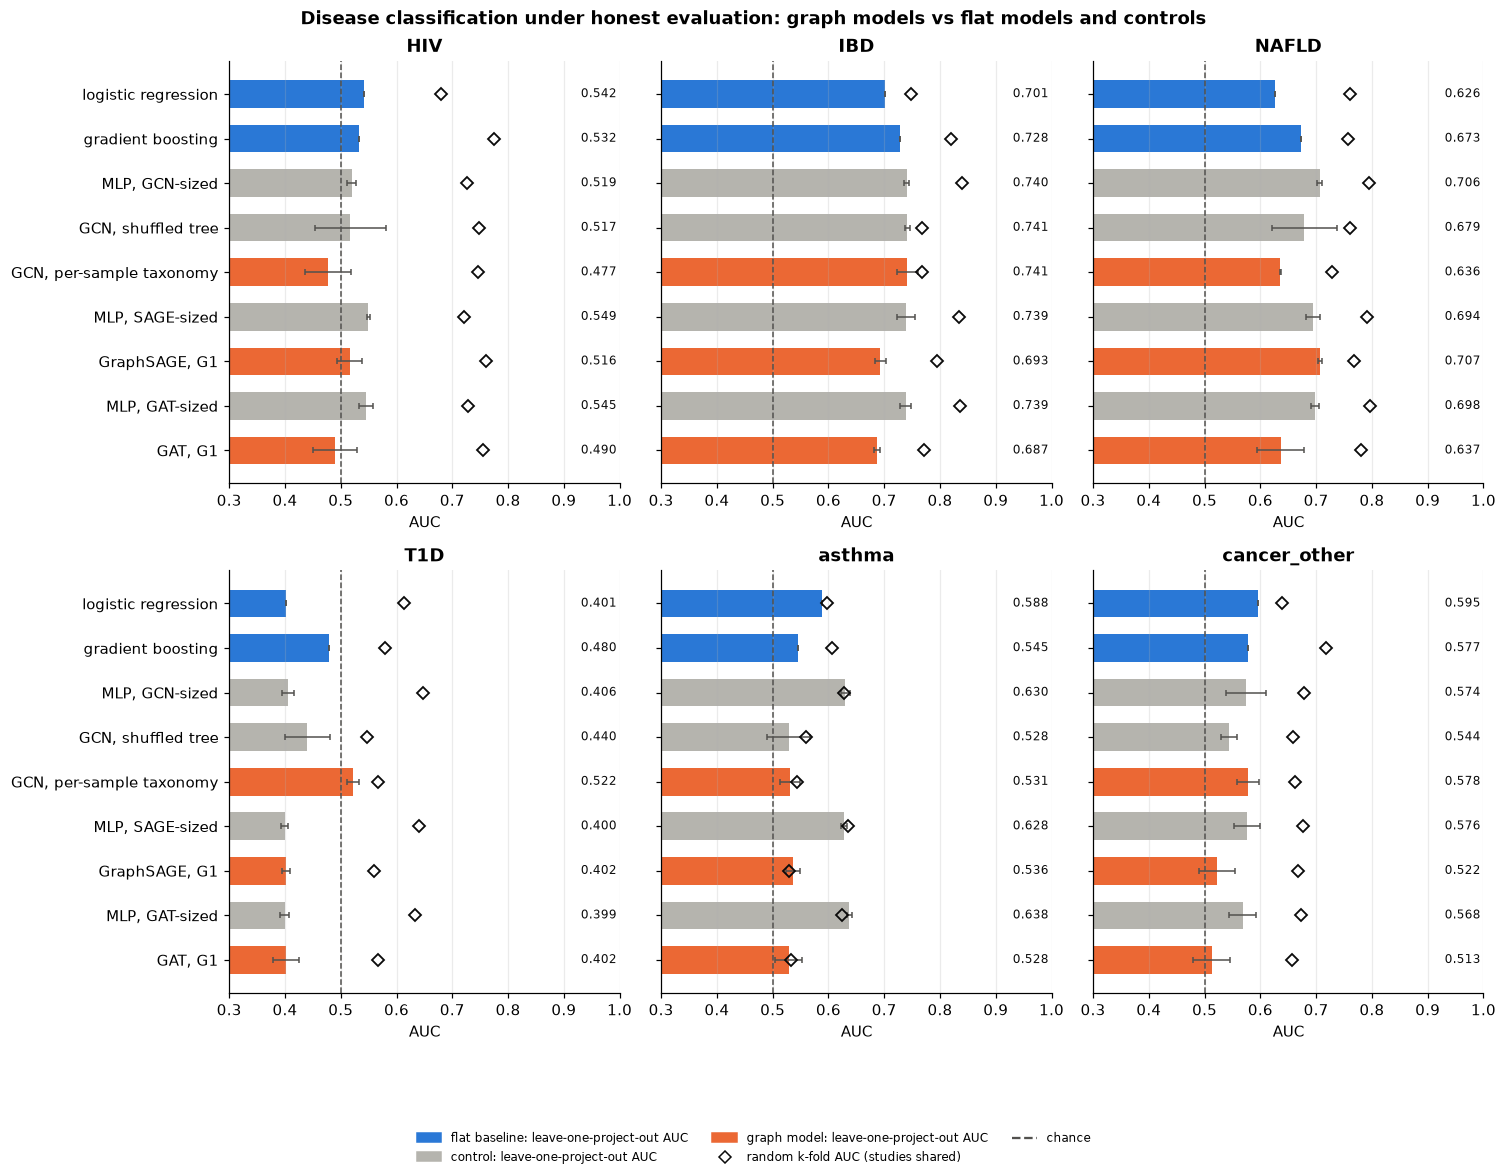

In [8]:
fig = gd.plot_disease_lopo(summary[summary["disease_category"].isin(bcfg["categories"])])
fig.savefig(FIGURES / "phase7_disease_lopo.png")